# Experimento 09f — Sensibilidad a variables con alta proporción de faltantes

Comparamos el umbral de faltantes del 50 % con el 75 % en los mismos cuatro cortes temporales. El análisis reutiliza las métricas de 09e y vuelve a entrenar únicamente Gradient Boosting para estudiar predicciones individuales y grupos según la disponibilidad real de las variables añadidas. No se usa el conjunto de prueba.

## 1. Diseño y cautelas

La selección de variables se calcula solo en el entrenamiento de cada corte. El modelo A usa las variables con hasta 50 % de faltantes; el modelo B agrega las que cumplen el umbral de 75 %. Ambos se ajustan sobre las mismas observaciones, con las mismas medianas de entrenamiento, codificación categórica e hiperparámetros de `HistGradientBoostingClassifier`.

Las tasas de faltantes observadas no prueban por sí solas por qué falta un valor. Para explorar cambios de registro, se compara la disponibilidad por año y se describe como posible cambio temporal cuando la cobertura aumenta. Esto es evidencia descriptiva, no causal. La imputación puede crear acumulación en la mediana; medimos su tamaño y lo distinguimos de valores que ya eran iguales a la mediana. No se interpreta esa acumulación como prueba de sobreajuste.

In [1]:
from pathlib import Path
import sys, time, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy import sparse

RAIZ=Path.cwd()
if not (RAIZ/"src").exists(): RAIZ=RAIZ.parent
if str(RAIZ) not in sys.path: sys.path.insert(0,str(RAIZ))
from src.config import localizar_datos, MAPA_OBJETIVO, SEMILLA
from src.modelado import TIPOS_AUDITADOS
from src import features as ft

SALIDA=RAIZ/"outputs"/"analisis_sensibilidad_faltantes"
SALIDA.mkdir(parents=True,exist_ok=True)
RUTA=localizar_datos()
RUTA_09E=RAIZ/"outputs"/"comparacion_umbrales_faltantes"
metricas_09e=pd.read_csv(RUTA_09E/"metricas_por_modelo_umbral_corte.csv")
resumen_09e=pd.read_csv(RUTA_09E/"resumen_promedios_y_variabilidad.csv")
selecciones_09e=pd.read_csv(RUTA_09E/"variables_seleccionadas_y_excluidas.csv")
UMBRALES=[50,75]
ANIOS=[2013,2014,2015,2016]
PARAM_GB={"learning_rate":0.08118441500491742,"max_iter":182,"max_leaf_nodes":31,
          "min_samples_leaf":46,"l2_regularization":0.32877474139911184,
          "early_stopping":False,"random_state":SEMILLA}
print("Archivo:",RUTA.name)
print("Se reutilizan las métricas de 09e; no se repetirán los modelos logístico y SVM.")

Archivo: accepted_2007_to_2018Q4.csv.gz
Se reutilizan las métricas de 09e; no se repetirán los modelos logístico y SVM.


## 2. Diferencia inicial entre umbrales 50 % y 75 %

La tabla combina promedios y variación entre años ya calculados en 09e. La diferencia positiva representa el cambio de 75 % menos 50 %.

In [2]:
comp=[]
for modelo in ["regresion_logistica","svm_lineal","gradient_boosting"]:
    for umbral in [50,75]:
        r=resumen_09e[(resumen_09e.modelo==modelo)&(resumen_09e.umbral_pct==umbral)].iloc[0]
        comp.append({"modelo":modelo,"umbral_pct":umbral,"variables_promedio":r.variables_promedio,
                     "ROC_AUC_promedio":r.ROC_AUC_promedio,"PR_AUC_promedio":r.PR_AUC_promedio,
                     "desv_ROC_AUC":r.ROC_AUC_desviacion,"desv_PR_AUC":r.PR_AUC_desviacion})
tabla_comparacion=pd.DataFrame(comp)
deltas=[]
for modelo in tabla_comparacion.modelo.unique():
    a=tabla_comparacion[(tabla_comparacion.modelo==modelo)&(tabla_comparacion.umbral_pct==50)].iloc[0]
    b=tabla_comparacion[(tabla_comparacion.modelo==modelo)&(tabla_comparacion.umbral_pct==75)].iloc[0]
    deltas.append({"modelo":modelo,"variables_adicionales_promedio":b.variables_promedio-a.variables_promedio,
                   "diferencia_ROC_AUC":b.ROC_AUC_promedio-a.ROC_AUC_promedio,
                   "diferencia_PR_AUC":b.PR_AUC_promedio-a.PR_AUC_promedio,
                   "desv_ROC_50":a.desv_ROC_AUC,"desv_ROC_75":b.desv_ROC_AUC,
                   "desv_PR_50":a.desv_PR_AUC,"desv_PR_75":b.desv_PR_AUC})
tabla_delta=pd.DataFrame(deltas)
display(tabla_comparacion.round(5)); display(tabla_delta.round(5))
metricas_anuales=metricas_09e[metricas_09e.umbral_pct.isin([50,75])].copy()
wide=metricas_anuales.pivot(index=["modelo","anio_validacion"],columns="umbral_pct",values=["ROC_AUC","PR_AUC","variables_originales"])
filas=[]
for (modelo,anio),r in wide.iterrows():
    filas.append({"modelo":modelo,"anio_validacion":anio,"variables_50":r[("variables_originales",50)],
                  "variables_75":r[("variables_originales",75)],"ROC_50":r[("ROC_AUC",50)],"ROC_75":r[("ROC_AUC",75)],
                  "delta_ROC_75_menos_50":r[("ROC_AUC",75)]-r[("ROC_AUC",50)],
                  "PR_50":r[("PR_AUC",50)],"PR_75":r[("PR_AUC",75)],
                  "delta_PR_75_menos_50":r[("PR_AUC",75)]-r[("PR_AUC",50)]})
metricas_por_anio=pd.DataFrame(filas)
display(metricas_por_anio.round(5))
tabla_comparacion.to_csv(SALIDA/"comparacion_promedios_50_vs_75.csv",index=False)
tabla_delta.to_csv(SALIDA/"diferencias_promedio_50_vs_75.csv",index=False)
metricas_por_anio.to_csv(SALIDA/"metricas_anuales_50_vs_75.csv",index=False)

,modelo,umbral_pct,variables_promedio,ROC_AUC_promedio,PR_AUC_promedio,desv_ROC_AUC,desv_PR_AUC
0,regresion_logistica,50,51.50,0.70219,0.35932,0.02386,0.07111
1,regresion_logistica,75,61.75,0.70548,0.36256,0.01819,0.06543
2,svm_lineal,50,51.50,0.70221,0.35857,0.02414,0.07108
3,svm_lineal,75,61.75,0.70537,0.36169,0.01869,0.06570
4,gradient_boosting,50,51.50,0.71043,0.36869,0.02591,0.07690
5,gradient_boosting,75,61.75,0.71351,0.37213,0.02025,0.07072


,modelo,variables_adicionales_promedio,diferencia_ROC_AUC,diferencia_PR_AUC,desv_ROC_50,desv_ROC_75,desv_PR_50,desv_PR_75
0,regresion_logistica,10.25,0.00330,0.00324,0.02386,0.01819,0.07111,0.06543
1,svm_lineal,10.25,0.00316,0.00312,0.02414,0.01869,0.07108,0.06570
2,gradient_boosting,10.25,0.00308,0.00344,0.02591,0.02025,0.07690,0.07072


,modelo,anio_validacion,variables_50,variables_75,ROC_50,ROC_75,delta_ROC_75_menos_50,PR_50,PR_75,delta_PR_75_menos_50
0,gradient_boosting,2013,26.0,61.0,0.67459,0.68712,0.01252,0.26500,0.27894,0.01394
1,gradient_boosting,2014,60.0,61.0,0.71317,0.71305,-0.00012,0.35615,0.35595,-0.00020
2,gradient_boosting,2015,60.0,62.0,0.73633,0.73624,-0.00009,0.42068,0.42070,0.00002
3,gradient_boosting,2016,60.0,63.0,0.71762,0.71762,-0.00000,0.43294,0.43295,0.00001
4,regresion_logistica,2013,26.0,61.0,0.66969,0.68267,0.01298,0.26307,0.27585,0.01277
5,regresion_logistica,2014,60.0,61.0,0.70532,0.70546,0.00013,0.34837,0.34847,0.00010
6,regresion_logistica,2015,60.0,62.0,0.72714,0.72717,0.00004,0.40835,0.40840,0.00005
7,regresion_logistica,2016,60.0,63.0,0.70659,0.70663,0.00003,0.41749,0.41754,0.00005
8,svm_lineal,2013,26.0,61.0,0.66941,0.68187,0.01246,0.26226,0.27443,0.01217
9,svm_lineal,2014,60.0,61.0,0.70589,0.70593,0.00005,0.34780,0.34784,0.00004


## 3. Carga reproducible de variables y selección por corte

Se recarga la misma población elegible usada en 09e, hasta 2016. `member_id` se conserva solo para considerar préstamos del mismo prestatario en el remuestreo de incertidumbre; nunca entra al modelo. `loan_status` construye el objetivo, `issue_d` define los años y ninguna de las dos se usa como predictor. Las candidatas se vuelven a obtener con las reglas de disponibilidad y exclusión de leakage del proyecto.

In [3]:
columnas_fuente=pd.read_csv(RUTA,nrows=0).columns.tolist()
candidatas=ft.seleccionar_predictoras(pd.DataFrame(columns=columnas_fuente),[],incluir_precio_lc=False)
cols_lectura=list(dict.fromkeys(candidatas+["loan_status","issue_d","member_id"]))
dtypes={c:("string" if TIPOS_AUDITADOS.get(c) in ["category","string"] else TIPOS_AUDITADOS.get(c,"string")) for c in cols_lectura}
dtypes["member_id"]="string"
partes=[]; t0=time.perf_counter()
with pd.read_csv(RUTA,usecols=cols_lectura,dtype=dtypes,chunksize=100_000,skipinitialspace=True,low_memory=False) as lector:
    for k,bloque in enumerate(lector,1):
        fechas=pd.to_datetime(bloque["issue_d"],format="%b-%Y",errors="coerce")
        mask=fechas.notna()&(fechas.dt.year<=2016)&bloque["loan_status"].isin(MAPA_OBJETIVO)
        bloque=bloque.loc[mask].copy()
        if bloque.empty: continue
        fechas=fechas.loc[mask]
        for c in ["earliest_cr_line","sec_app_earliest_cr_line"]:
            if c in bloque:
                original=bloque[c].notna()
                conv=pd.to_datetime(bloque[c],format="%b-%Y",errors="coerce")
                if (original&conv.isna()).any(): raise ValueError(f"Fecha ilegible en {c}")
                bloque[c]=conv
        if "term" in bloque:
            bloque["term"]=pd.to_numeric(bloque["term"].astype("string").str.strip().str.replace(" months","",regex=False),errors="raise").astype("float64")
        bloque["fecha_prestamo"]=fechas
        bloque["anio"]=fechas.dt.year.astype("int16")
        bloque["default"]=bloque.loan_status.map(MAPA_OBJETIVO).astype("int8")
        partes.append(bloque)
        if k%10==0: print(f"Bloques leídos: {k}",flush=True)
datos=pd.concat(partes,ignore_index=True)
assert datos.anio.max()<=2016
print(f"Población elegible hasta 2016: {len(datos):,}; carga {time.perf_counter()-t0:.1f} s; candidatas: {len(candidatas)}")

def preparar_X(tabla,fecha_otorgamiento):
    X=tabla.copy()
    for c in ["earliest_cr_line","sec_app_earliest_cr_line"]:
        if c in X:
            inicio=X[c]
            X["meses_desde_"+c]=((fecha_otorgamiento.dt.year-inicio.dt.year)*12+(fecha_otorgamiento.dt.month-inicio.dt.month)).astype("float64")
            X=X.drop(columns=c)
    for c in X.columns:
        if pd.api.types.is_numeric_dtype(X[c]):
            X[c]=pd.to_numeric(X[c],errors="coerce").astype("float64").replace([np.inf,-np.inf],np.nan)
        else:
            X[c]=X[c].astype(object).where(X[c].notna(),np.nan)
    return X

def construir_preprocesador(Xtr):
    numericas=[c for c in Xtr if pd.api.types.is_numeric_dtype(Xtr[c])]
    categoricas=[c for c in Xtr if c not in numericas]
    transformadores=[]
    if numericas:
        transformadores.append(("numericas",Pipeline([("imputar",SimpleImputer(strategy="median")),
            ("escalar",StandardScaler(with_mean=True))]),numericas))
    if categoricas:
        transformadores.append(("categoricas",Pipeline([("imputar",SimpleImputer(strategy="constant",fill_value="Sin información")),
            ("onehot",OneHotEncoder(handle_unknown="ignore",drop="first",sparse_output=False,dtype=np.float32))]),categoricas))
    return ColumnTransformer(transformadores,remainder="drop",sparse_threshold=0.0)


Bloques leídos: 10


Bloques leídos: 20


Población elegible hasta 2016: 1,119,699; carga 47.8 s; candidatas: 95


## 4. Características agregadas al pasar de 50 % a 75 %

Para cada corte se identifican las candidatas admitidas al 75 % pero no al 50 %. Se muestra su porcentaje faltante en entrenamiento y validación, y cuántos valores observados hay. También se compara su disponibilidad por año para detectar patrones compatibles con cambios temporales de recopilación.

Variables nuevas por corte:


,variables_adicionales,faltantes_train_promedio_pct,faltantes_validacion_promedio_pct
anio_validacion,,,
2013,35,66.14,2.12
2014,1,58.47,49.15
2015,2,61.99,56.05
2016,3,64.50,60.69


,anio_validacion,anio_final_entrenamiento,variable,faltante_pct_entrenamiento,faltante_pct_validacion,observados_entrenamiento,faltantes_entrenamiento,observados_validacion,faltantes_validacion,tipo
8,2013,2012,mo_sin_old_il_acct,73.75,3.68,24450,68703,129849,4955,numerica
9,2013,2012,mo_sin_old_rev_tl_op,72.49,0.00,25625,67528,134804,0,numerica
10,2013,2012,mo_sin_rcnt_rev_tl_op,72.49,0.00,25625,67528,134804,0,numerica
1,2013,2012,tot_coll_amt,72.49,0.00,25626,67527,134804,0,numerica
2,2013,2012,tot_cur_bal,72.49,0.00,25626,67527,134804,0,numerica
3,2013,2012,total_rev_hi_lim,72.49,0.00,25626,67527,134804,0,numerica
5,2013,2012,avg_cur_bal,72.49,0.00,25626,67527,134798,6,numerica
11,2013,2012,mo_sin_rcnt_tl,72.49,0.00,25626,67527,134804,0,numerica
15,2013,2012,num_accts_ever_120_pd,72.49,0.00,25626,67527,134804,0,numerica
16,2013,2012,num_actv_bc_tl,72.49,0.00,25626,67527,134804,0,numerica


,variable,primer_anio_con_80pct_observado,anios_previos_con_menos_50pct_observado,patron_compatible_con_aumento_temporal_de_cobertura,nota
0,acc_open_past_24mths,2012.0,5,"Sí, posible",Descripción de cobertura; no demuestra la caus...
1,avg_cur_bal,2013.0,6,"Sí, posible",Descripción de cobertura; no demuestra la caus...
2,bc_open_to_buy,2012.0,5,"Sí, posible",Descripción de cobertura; no demuestra la caus...
3,bc_util,2012.0,5,"Sí, posible",Descripción de cobertura; no demuestra la caus...
4,mo_sin_old_il_acct,2013.0,6,"Sí, posible",Descripción de cobertura; no demuestra la caus...
5,mo_sin_old_rev_tl_op,2013.0,6,"Sí, posible",Descripción de cobertura; no demuestra la caus...
6,mo_sin_rcnt_rev_tl_op,2013.0,6,"Sí, posible",Descripción de cobertura; no demuestra la caus...
7,mo_sin_rcnt_tl,2013.0,6,"Sí, posible",Descripción de cobertura; no demuestra la caus...
8,mort_acc,2012.0,5,"Sí, posible",Descripción de cobertura; no demuestra la caus...
9,mths_since_last_delinq,2007.0,0,No claro,Descripción de cobertura; no demuestra la caus...


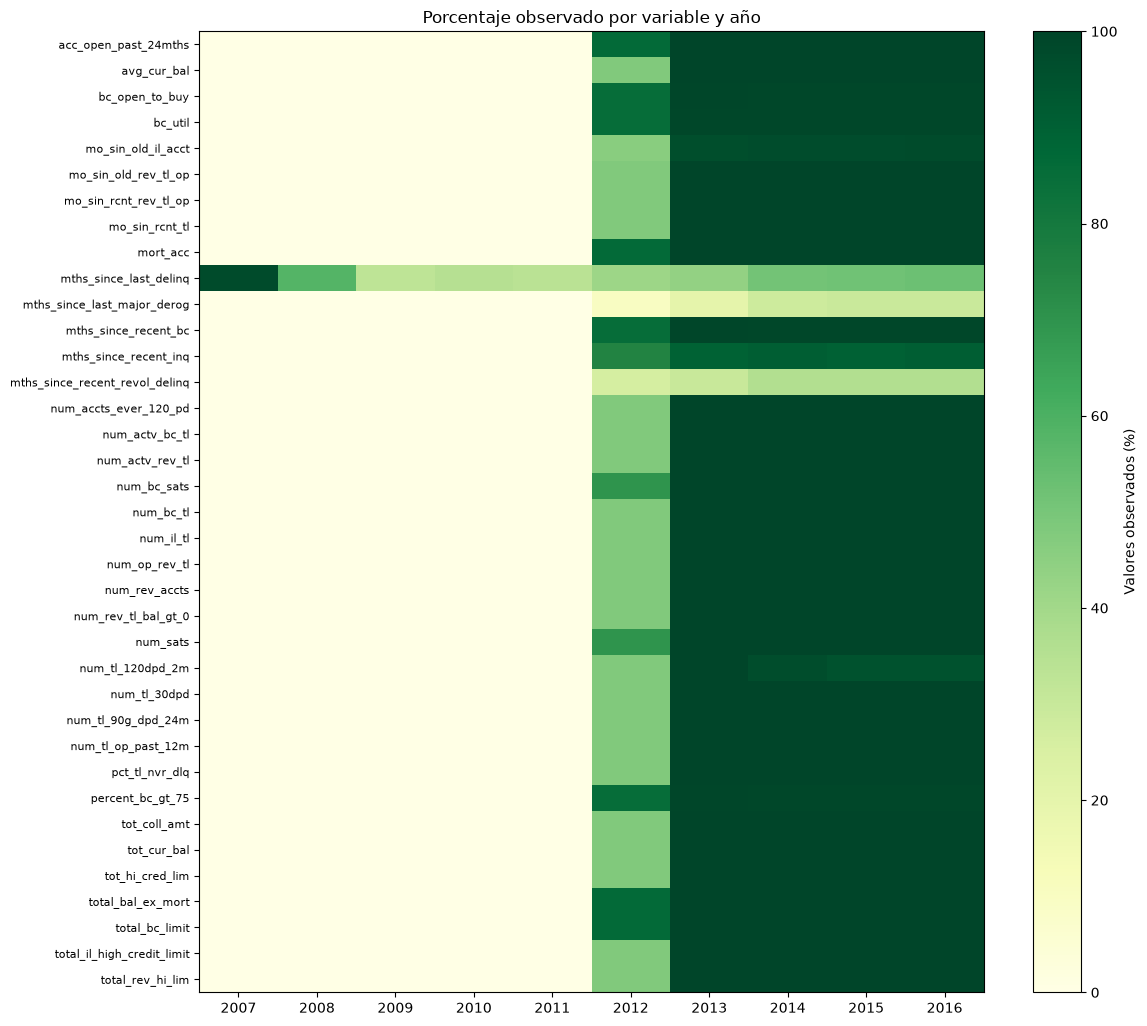

In [4]:
adiciones=[]
for anio in ANIOS:
    mtr=datos.anio<anio; mva=datos.anio==anio
    s50=selecciones_09e[(selecciones_09e.anio_validacion==anio)&(selecciones_09e.umbral_pct==50)&selecciones_09e.seleccionada].variable.tolist()
    s75=selecciones_09e[(selecciones_09e.anio_validacion==anio)&(selecciones_09e.umbral_pct==75)&selecciones_09e.seleccionada].variable.tolist()
    extras=[c for c in s75 if c not in s50]
    for c in extras:
        tr=datos.loc[mtr,c]; va=datos.loc[mva,c]
        adiciones.append({"anio_validacion":anio,"anio_final_entrenamiento":anio-1,"variable":c,
            "faltante_pct_entrenamiento":tr.isna().mean()*100,"faltante_pct_validacion":va.isna().mean()*100,
            "observados_entrenamiento":int(tr.notna().sum()),"faltantes_entrenamiento":int(tr.isna().sum()),
            "observados_validacion":int(va.notna().sum()),"faltantes_validacion":int(va.isna().sum()),
            "tipo":"numerica" if pd.api.types.is_numeric_dtype(tr) else "categorica"})
variables_adicionales=pd.DataFrame(adiciones)
print("Variables nuevas por corte:")
display(variables_adicionales.groupby("anio_validacion").agg(variables_adicionales=("variable","nunique"),
    faltantes_train_promedio_pct=("faltante_pct_entrenamiento","mean"),faltantes_validacion_promedio_pct=("faltante_pct_validacion","mean")).round(2))
display(variables_adicionales.sort_values(["anio_validacion","faltante_pct_entrenamiento"],ascending=[True,False]).round(2))

union_extra=variables_adicionales.variable.drop_duplicates().tolist()
if union_extra:
    por_anio=datos.groupby("anio")[union_extra].agg(["count","size"])
    disponibilidad=[]
    for c in union_extra:
        for anio in por_anio.index:
            obs=int(por_anio.loc[anio,(c,"count")]); n=int(por_anio.loc[anio,(c,"size")])
            disponibilidad.append({"variable":c,"anio":int(anio),"registros":n,"observados":obs,
                "faltantes":n-obs,"observado_pct":100*obs/n if n else np.nan,"faltante_pct":100*(n-obs)/n if n else np.nan})
    disponibilidad_anual=pd.DataFrame(disponibilidad)
    tendencia=[]
    for c,g in disponibilidad_anual.groupby("variable"):
        g=g.sort_values("anio"); suficientes=g[g.observado_pct>=80]
        inicio=int(suficientes.anio.iloc[0]) if len(suficientes) else np.nan
        antes=g[g.anio<inicio] if pd.notna(inicio) else g.iloc[0:0]
        claro=bool(len(antes)>=2 and (antes.observado_pct<50).all())
        tendencia.append({"variable":c,"primer_anio_con_80pct_observado":inicio,
            "anios_previos_con_menos_50pct_observado":int(len(antes)),
            "patron_compatible_con_aumento_temporal_de_cobertura":"Sí, posible" if claro else "No claro",
            "nota":"Descripción de cobertura; no demuestra la causa de los faltantes"})
    tendencia_disponibilidad=pd.DataFrame(tendencia)
    display(tendencia_disponibilidad)
    # Matriz de disponibilidad por año; colores oscuros indican más valores observados.
    matriz=disponibilidad_anual.pivot(index="variable",columns="anio",values="observado_pct")
    fig,ax=plt.subplots(figsize=(12,max(6,0.28*len(matriz))))
    im=ax.imshow(matriz.to_numpy(),aspect="auto",cmap="YlGn",vmin=0,vmax=100)
    ax.set_xticks(range(len(matriz.columns)),labels=matriz.columns)
    ax.set_yticks(range(len(matriz.index)),labels=matriz.index,fontsize=8)
    ax.set_title("Porcentaje observado por variable y año")
    fig.colorbar(im,ax=ax,label="Valores observados (%)"); fig.tight_layout()
    fig.savefig(SALIDA/"01_disponibilidad_anual.png",dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)
else:
    disponibilidad_anual=pd.DataFrame(); tendencia_disponibilidad=pd.DataFrame()
variables_adicionales.to_csv(SALIDA/"variables_adicionales_por_corte.csv",index=False)
disponibilidad_anual.to_csv(SALIDA/"disponibilidad_anual_variables.csv",index=False)
tendencia_disponibilidad.to_csv(SALIDA/"resumen_tendencia_disponibilidad.csv",index=False)

## 5. Qué cambia al imputar con la mediana

Para un máximo de cuatro características numéricas representativas, se mide la proporción de valores imputados y cuántos quedan exactamente en la mediana. Se separa el porcentaje que ya era igual a la mediana antes de rellenar del aumento debido a la imputación. Los histogramas comparan valores observados e imputados en entrenamiento y validación; la mediana siempre procede del entrenamiento.

,variable,corte_validacion,conjunto,filas,faltantes_originales_pct,mediana_entrenamiento,observados_ya_iguales_mediana_pct,valores_rellenados_pct,valores_finales_iguales_mediana_pct,aumento_por_imputacion_puntos
0,mths_since_last_major_derog,2016,entrenamiento,826604,74.924,43.0,0.388,74.924,75.312,73.763
1,mths_since_last_major_derog,2016,validacion,293095,70.660,43.0,0.474,70.660,71.134,69.518
2,mo_sin_old_il_acct,2013,entrenamiento,93153,73.753,126.0,0.294,73.753,74.047,72.926
3,mo_sin_old_il_acct,2013,validacion,134804,3.676,126.0,1.136,3.676,4.811,3.632
4,mo_sin_old_rev_tl_op,2013,entrenamiento,93153,72.491,156.0,0.187,72.491,72.678,71.999
5,mo_sin_old_rev_tl_op,2013,validacion,134804,0.000,156.0,0.637,0.000,0.637,0.000
6,mo_sin_rcnt_rev_tl_op,2013,entrenamiento,93153,72.491,9.0,1.112,72.491,73.604,69.561
7,mo_sin_rcnt_rev_tl_op,2013,validacion,134804,0.000,9.0,4.133,0.000,4.133,0.000


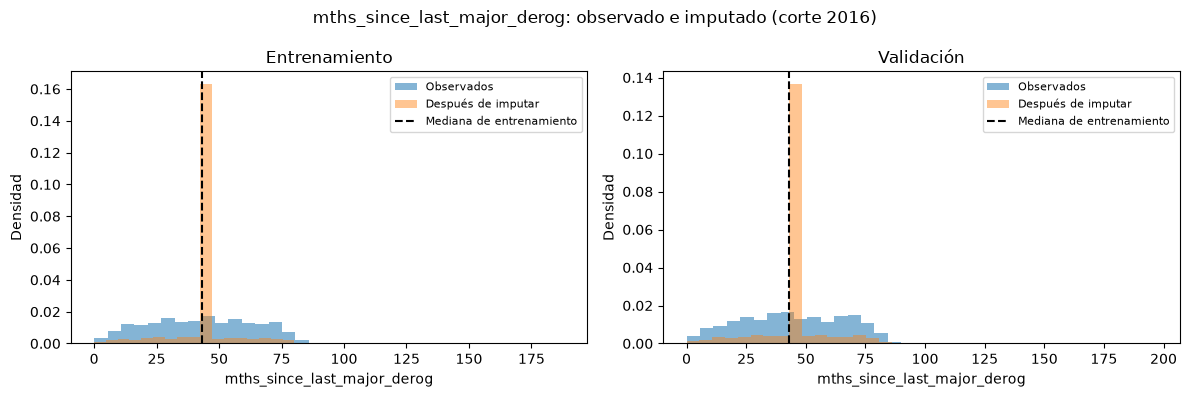

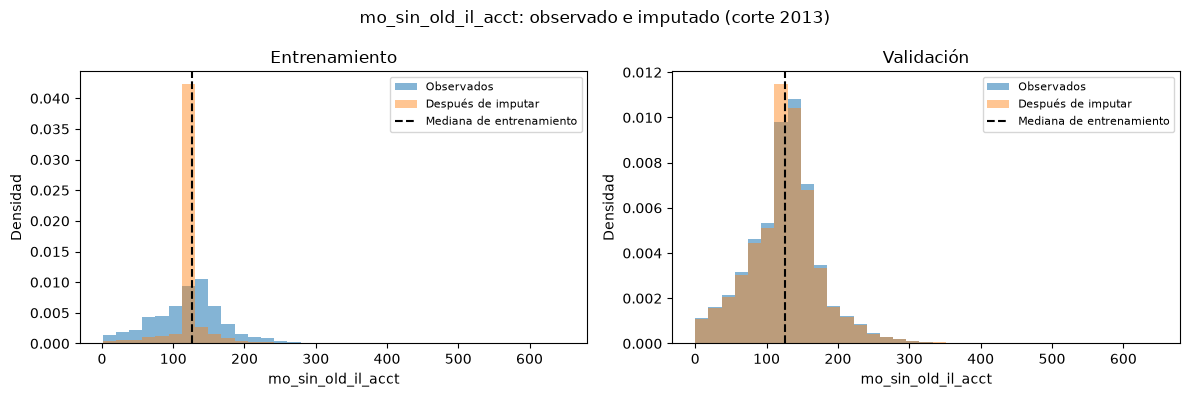

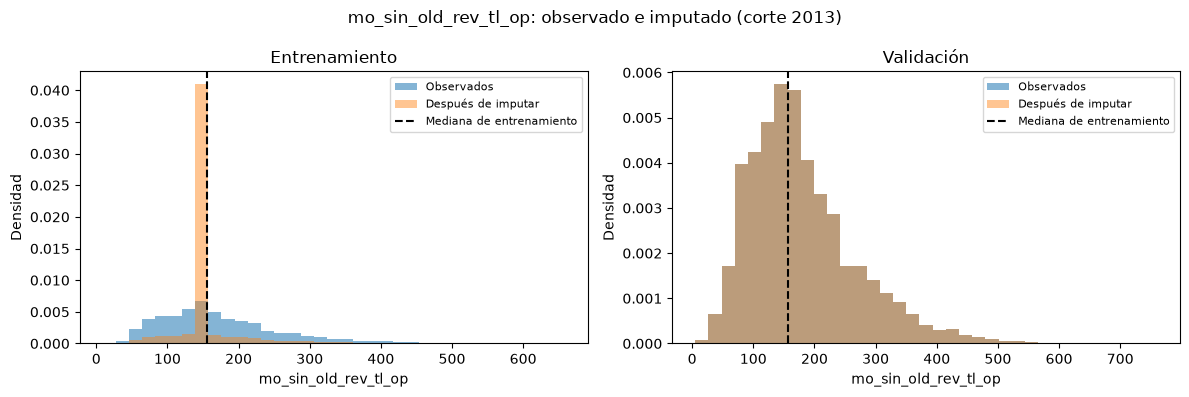

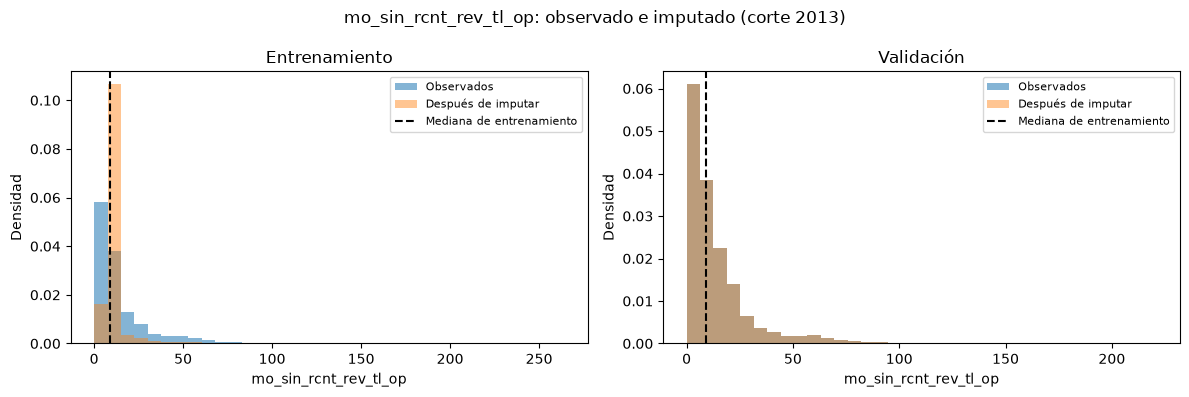

In [5]:
vars_repr=(variables_adicionales.groupby("variable").faltante_pct_entrenamiento.mean()
           .sort_values(ascending=False).head(4).index.tolist())
resumen_imputacion=[]
for c in vars_repr:
    fila=variables_adicionales[variables_adicionales.variable==c].sort_values("faltante_pct_entrenamiento",ascending=False).iloc[0]
    anio=int(fila.anio_validacion); mtr=datos.anio<anio; mva=datos.anio==anio
    xtr=datos.loc[mtr,c]; xva=datos.loc[mva,c]
    if not pd.api.types.is_numeric_dtype(xtr): continue
    med=float(xtr.median())
    for conjunto,x in [("entrenamiento",xtr),("validacion",xva)]:
        filled=x.fillna(med)
        resumen_imputacion.append({"variable":c,"corte_validacion":anio,"conjunto":conjunto,
            "filas":len(x),"faltantes_originales_pct":x.isna().mean()*100,
            "mediana_entrenamiento":med,"observados_ya_iguales_mediana_pct":(x.eq(med).sum()/len(x))*100,
            "valores_rellenados_pct":x.isna().mean()*100,
            "valores_finales_iguales_mediana_pct":filled.eq(med).mean()*100,
            "aumento_por_imputacion_puntos":(filled.eq(med).mean()-x.eq(med).mean())*100})
resumen_imputacion=pd.DataFrame(resumen_imputacion)
display(resumen_imputacion.round(3))
resumen_imputacion.to_csv(SALIDA/"resumen_efecto_imputacion.csv",index=False)

# Histogramas de hasta cuatro variables, muestreados solo para dibujar.
for c in vars_repr:
    if c not in datos or not pd.api.types.is_numeric_dtype(datos[c]): continue
    fila=variables_adicionales[variables_adicionales.variable==c].sort_values("faltante_pct_entrenamiento",ascending=False).iloc[0]
    anio=int(fila.anio_validacion); xtr=datos.loc[datos.anio<anio,c]; xva=datos.loc[datos.anio==anio,c]
    med=float(xtr.median()); fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,x,nombre in [(axes[0],xtr,"Entrenamiento"),(axes[1],xva,"Validación")]:
        observed=x.dropna(); filled=x.fillna(med)
        if len(observed)>100_000: observed=observed.sample(100_000,random_state=42)
        if len(filled)>100_000: filled=filled.sample(100_000,random_state=42)
        ax.hist(observed,bins=35,density=True,alpha=.55,label="Observados")
        ax.hist(filled,bins=35,density=True,alpha=.45,label="Después de imputar")
        ax.axvline(med,color="black",linestyle="--",label="Mediana de entrenamiento")
        ax.set_title(nombre); ax.set_xlabel(c); ax.set_ylabel("Densidad"); ax.legend(fontsize=8)
    fig.suptitle(f"{c}: observado e imputado (corte {anio})"); fig.tight_layout()
    fig.savefig(SALIDA/f"02_distribucion_{c}.png",dpi=150,bbox_inches="tight"); display(fig); plt.close(fig)

## 6. Contribución de las variables adicionales en Gradient Boosting

Se vuelven a entrenar solo los modelos A y B en cada corte (ocho ajustes en total). Se generan predicciones para los mismos préstamos de validación; luego se comparan las métricas globales y por grupos definidos según cuántas variables adicionales tenían un dato observado antes de imputar. El conteo se calcula en validación sin mirar el resultado objetivo. En cada grupo se informa tamaño y prevalencia de `Charged Off`, porque AP depende de esa prevalencia.

In [6]:
predicciones=[]; resumen_modelos=[]; metricas_grupo=[]; bootstrap_rows=[]
rng=np.random.default_rng(2026)
for anio in ANIOS:
    mtr=datos.anio<anio; mva=datos.anio==anio
    train=datos.loc[mtr]; valid=datos.loc[mva]
    ytr=train.default.to_numpy(dtype="int8"); yva=valid.default.to_numpy(dtype="int8")
    s50=selecciones_09e[(selecciones_09e.anio_validacion==anio)&(selecciones_09e.umbral_pct==50)&selecciones_09e.seleccionada].variable.tolist()
    s75=selecciones_09e[(selecciones_09e.anio_validacion==anio)&(selecciones_09e.umbral_pct==75)&selecciones_09e.seleccionada].variable.tolist()
    extras=[c for c in s75 if c not in s50]
    por_modelo={}
    for nombre,cols in [("A_50pct",s50),("B_75pct",s75)]:
        Xtr=preparar_X(train[cols],train.fecha_prestamo)
        Xva=preparar_X(valid[cols],valid.fecha_prestamo)
        pre=construir_preprocesador(Xtr)
        Xtr2=pre.fit_transform(Xtr); Xva2=pre.transform(Xva)
        clf=HistGradientBoostingClassifier(**PARAM_GB)
        inicio=time.perf_counter(); clf.fit(Xtr2,ytr); segundos=time.perf_counter()-inicio
        score=clf.predict_proba(Xva2)[:,1]
        por_modelo[nombre]=score
        resumen_modelos.append({"anio_validacion":anio,"modelo":nombre,"filas_entrenamiento":len(ytr),
            "filas_validacion":len(yva),"variables_originales":len(cols),"variables_adicionales":len(extras),
            "ROC_AUC":roc_auc_score(yva,score),"PR_AUC":average_precision_score(yva,score),"segundos_ajuste":segundos})
        predicciones.append(pd.DataFrame({"anio_validacion":anio,"indice_registro":valid.index.to_numpy(),
            "default":yva,"modelo":nombre,"score":score}))
        del pre,Xtr2,Xva2,clf
        gc.collect()
    score_a=por_modelo["A_50pct"]; score_b=por_modelo["B_75pct"]
    assert len(score_a)==len(score_b)==len(yva)
    n_extra=len(extras)
    if n_extra:
        observado=valid[extras].notna().sum(axis=1).to_numpy()
        # Grupos relativos al total de variables añadidas, sin usar la etiqueta.
        def grupo_observacion(n):
            if n==0: return "ninguna_observada"
            if n==n_extra: return "todas_observadas"
            if n*2<=n_extra: return "hasta_la_mitad_observadas"
            return "mas_de_la_mitad_observadas"
        grupos=np.array([grupo_observacion(int(n)) for n in observado],dtype=object)
    else:
        grupos=np.repeat("sin_variables_adicionales",len(yva))
    for grupo in pd.unique(grupos):
        ix=grupos==grupo; yy=yva[ix]
        auc_a=roc_auc_score(yy,score_a[ix]) if len(np.unique(yy))==2 else np.nan
        auc_b=roc_auc_score(yy,score_b[ix]) if len(np.unique(yy))==2 else np.nan
        ap_a=average_precision_score(yy,score_a[ix]) if yy.sum()>0 else np.nan
        ap_b=average_precision_score(yy,score_b[ix]) if yy.sum()>0 else np.nan
        metricas_grupo.append({"anio_validacion":anio,"grupo_disponibilidad":grupo,"variables_adicionales":n_extra,
            "prestamos":int(ix.sum()),"charged_off":int(yy.sum()),"prevalencia_charged_off_pct":float(yy.mean()*100),
            "ROC_AUC_A_50":auc_a,"ROC_AUC_B_75":auc_b,"delta_ROC_AUC":auc_b-auc_a if np.isfinite(auc_a+auc_b) else np.nan,
            "PR_AUC_A_50":ap_a,"PR_AUC_B_75":ap_b,"delta_PR_AUC":ap_b-ap_a if np.isfinite(ap_a+ap_b) else np.nan})
    # Bootstrap pareado por prestatario para la diferencia de ROC-AUC B-A.
    ids=valid.member_id.astype("string").to_numpy()
    ids=np.array([f"missing_row_{i}" if pd.isna(v) else str(v) for i,v in enumerate(ids)],dtype=object)
    group_code,_=pd.factorize(ids,sort=False)
    clusters=np.unique(group_code)
    indices_by_cluster=[np.flatnonzero(group_code==g) for g in clusters]
    deltas_boot=[]
    for b in range(200):
        picks=rng.integers(0,len(indices_by_cluster),size=len(indices_by_cluster))
        ix=np.concatenate([indices_by_cluster[j] for j in picks])
        yy=yva[ix]
        if len(np.unique(yy))<2: continue
        deltas_boot.append(roc_auc_score(yy,score_b[ix])-roc_auc_score(yy,score_a[ix]))
    bootstrap_rows.append({"anio_validacion":anio,"delta_ROC_AUC":roc_auc_score(yva,score_b)-roc_auc_score(yva,score_a),
        "intervalo_95_inferior":np.quantile(deltas_boot,.025),"intervalo_95_superior":np.quantile(deltas_boot,.975),
        "repeticiones_validas":len(deltas_boot),"unidad_remuestreo":"member_id (prestatario)"})
    print(f"{anio}: +{n_extra} variables; AUC {roc_auc_score(yva,score_a):.5f} → {roc_auc_score(yva,score_b):.5f}; AP {average_precision_score(yva,score_a):.5f} → {average_precision_score(yva,score_b):.5f}",flush=True)
    del por_modelo,score_a,score_b,train,valid
    gc.collect()

predicciones=pd.concat(predicciones,ignore_index=True)
metricas_gb=pd.DataFrame(resumen_modelos)
metricas_por_grupo=pd.DataFrame(metricas_grupo)
intervalos_bootstrap=pd.DataFrame(bootstrap_rows)
display(metricas_gb.round(5)); display(metricas_por_grupo.round(5)); display(intervalos_bootstrap.round(5))
predicciones.to_csv(SALIDA/"predicciones_gradient_boosting_50_75.csv",index=False)
metricas_gb.to_csv(SALIDA/"metricas_gradient_boosting_por_anio.csv",index=False)
metricas_por_grupo.to_csv(SALIDA/"metricas_por_disponibilidad_observada.csv",index=False)
intervalos_bootstrap.to_csv(SALIDA/"intervalos_pareados_ROC_por_prestatario.csv",index=False)

2013: +35 variables; AUC 0.67459 → 0.68712; AP 0.26500 → 0.27894


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


2014: +1 variables; AUC 0.71317 → 0.71305; AP 0.35615 → 0.35595


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


2015: +2 variables; AUC 0.73633 → 0.73624; AP 0.42068 → 0.42070


2016: +3 variables; AUC 0.71762 → 0.71762; AP 0.43294 → 0.43295


,anio_validacion,modelo,filas_entrenamiento,filas_validacion,variables_originales,variables_adicionales,ROC_AUC,PR_AUC,segundos_ajuste
0,2013,A_50pct,93153,134804,26,35,0.67459,0.26500,3.05949
1,2013,B_75pct,93153,134804,61,35,0.68712,0.27894,1.62340
2,2014,A_50pct,227957,223102,60,1,0.71317,0.35615,3.95863
3,2014,B_75pct,227957,223102,61,1,0.71305,0.35595,4.06616
4,2015,A_50pct,451059,375545,60,2,0.73633,0.42068,9.32516
5,2015,B_75pct,451059,375545,62,2,0.73624,0.42070,9.37346
6,2016,A_50pct,826604,293095,60,3,0.71762,0.43294,19.97304
7,2016,B_75pct,826604,293095,63,3,0.71762,0.43295,20.03551


,anio_validacion,grupo_disponibilidad,variables_adicionales,prestamos,charged_off,prevalencia_charged_off_pct,ROC_AUC_A_50,ROC_AUC_B_75,delta_ROC_AUC,PR_AUC_A_50,PR_AUC_B_75,delta_PR_AUC
0,2013,mas_de_la_mitad_observadas,35,83387,12825,15.38010,0.68008,0.69359,0.01351,0.26375,0.27917,0.01543
1,2013,todas_observadas,35,51417,8199,15.94609,0.66668,0.67663,0.00995,0.26765,0.27890,0.01124
2,2014,todas_observadas,1,113456,21422,18.88133,0.70227,0.70255,0.00028,0.35346,0.35273,-0.00072
3,2014,ninguna_observada,1,109646,19739,18.00248,0.72426,0.72372,-0.00054,0.35919,0.35960,0.00041
4,2015,todas_observadas,2,135622,28036,20.67216,0.72750,0.72724,-0.00026,0.41930,0.41915,-0.00015
5,2015,ninguna_observada,2,181080,35348,19.52065,0.74447,0.74436,-0.00011,0.41761,0.41773,0.00011
6,2015,hasta_la_mitad_observadas,2,58843,12419,21.10531,0.73111,0.73153,0.00042,0.43303,0.43335,0.00032
7,2016,ninguna_observada,3,135924,30418,22.37868,0.72899,0.72892,-0.00007,0.43317,0.43296,-0.00021
8,2016,mas_de_la_mitad_observadas,3,75157,17740,23.60392,0.70995,0.71026,0.00032,0.42716,0.42782,0.00066
9,2016,todas_observadas,3,56670,13979,24.66737,0.70238,0.70221,-0.00017,0.43740,0.43746,0.00006


,anio_validacion,delta_ROC_AUC,intervalo_95_inferior,intervalo_95_superior,repeticiones_validas,unidad_remuestreo
0,2013,0.01252,0.01024,0.01464,200,member_id (prestatario)
1,2014,-0.00012,-0.00062,0.00036,200,member_id (prestatario)
2,2015,-0.00009,-0.00037,0.00016,200,member_id (prestatario)
3,2016,-0.00000,-0.00026,0.00027,200,member_id (prestatario)


## 7. Conclusiones y decisión

La decisión debe considerar el tamaño de la ganancia, su repetición entre años, las características que la producen y cuánta información de ellas se completa artificialmente. Las diferencias entre A y B no prueban que añadir variables cause una mejora; representan una comparación predictiva bajo estos cortes y este preprocesamiento. Los intervalos por `member_id` consideran que un prestatario puede tener más de un préstamo, pero no eliminan el riesgo de elegir entre umbrales usando los mismos años de validación.

Adiciones únicas por corte: {2013: 35, 2014: 1, 2015: 2, 2016: 3}
Delta promedio de ROC-AUC GB (75%-50%): 0.00308; mejora en 1/4 años.
Delta promedio de PR-AUC GB (75%-50%): 0.00344; mejora en 3/4 años.
Las tablas de imputación cuantifican cuánto se completa; revisarlas junto con el gráfico de disponibilidad y los grupos de observabilidad.
Recomendación basada en métricas agregadas: El aumento al 75 % no ofrece una mejora suficientemente consistente entre años; el 50 % es la opción más conservadora hasta obtener nueva evidencia.
La decisión final también debe considerar tamaños de los grupos observados, intervalos pareados y proporción imputada; las diferencias por grupo son descriptivas, no causales.


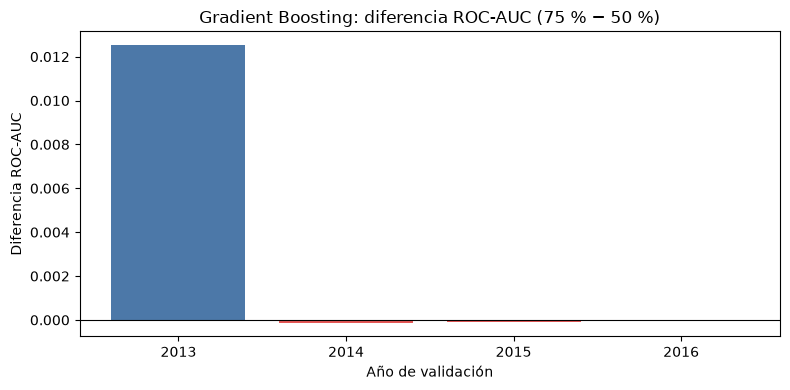

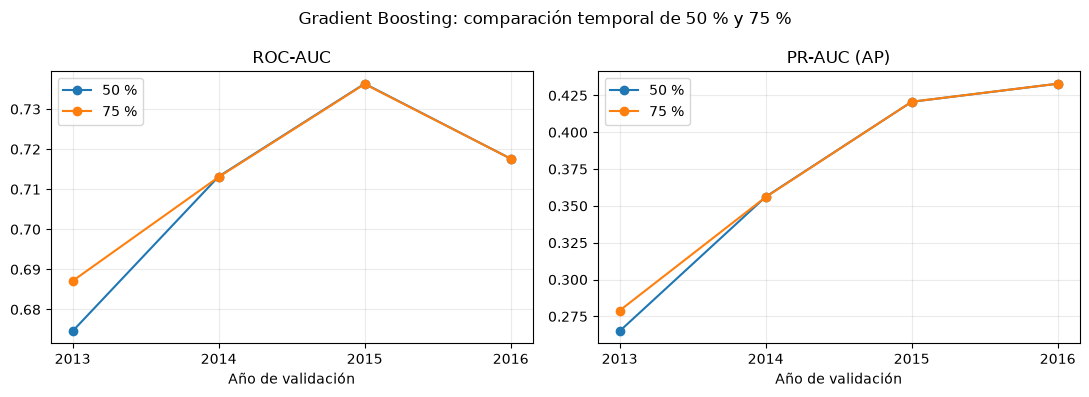


Conclusiones por criterio:
1) El umbral 75% incorpora 37 variables distintas a lo largo de los cortes; por año: {2013: 35, 2014: 1, 2015: 2, 2016: 3}.
   2013: faltan 66.1% de las celdas adicionales en entrenamiento y 2.1% en validación.
   2014: faltan 58.5% de las celdas adicionales en entrenamiento y 49.1% en validación.
   2015: faltan 62.0% de las celdas adicionales en entrenamiento y 56.1% en validación.
   2016: faltan 64.5% de las celdas adicionales en entrenamiento y 60.7% en validación.
2) En el corte de 2013, el gran bloque de características adicionales cambia de 66.1% faltante en entrenamiento a 2.1% en validación; esto muestra un fuerte cambio de cobertura temporal.
3) La diferencia media de Gradient Boosting es ROC-AUC +0.00308 y PR-AUC +0.00344, pero la ganancia se concentra en 2013.
4) En 2014–2016 las diferencias de ROC-AUC son [-0.000123, -8.5e-05, -3e-06] y las de PR-AUC [-0.000203, 1.7e-05, 5e-06].
5) En 2013, B mejora ROC-AUC en los grupos donde las variables aña

In [2]:
# Resumen generado a partir de los resultados del notebook.
base=metricas_gb.pivot(index="anio_validacion",columns="modelo",values=["ROC_AUC","PR_AUC"])
base["delta_roc"]=base[("ROC_AUC","B_75pct")]-base[("ROC_AUC","A_50pct")]
base["delta_pr"]=base[("PR_AUC","B_75pct")]-base[("PR_AUC","A_50pct")]
mejoras_roc=int((base.delta_roc>0).sum()); mejoras_pr=int((base.delta_pr>0).sum())
mean_roc=float(base.delta_roc.mean()); mean_pr=float(base.delta_pr.mean())
extras_por_corte=variables_adicionales.groupby("anio_validacion").variable.nunique().to_dict()
print("Adiciones únicas por corte:",extras_por_corte)
print(f"Delta promedio de ROC-AUC GB (75%-50%): {mean_roc:.5f}; mejora en {mejoras_roc}/4 años.")
print(f"Delta promedio de PR-AUC GB (75%-50%): {mean_pr:.5f}; mejora en {mejoras_pr}/4 años.")
print("Las tablas de imputación cuantifican cuánto se completa; revisarlas junto con el gráfico de disponibilidad y los grupos de observabilidad.")
if mean_roc>0.002 and mean_pr>0.002 and mejoras_roc>=3 and mejoras_pr>=3:
    recomendacion="Los resultados favorecen provisionalmente 75 %: la ganancia media es apreciable y aparece en la mayoría de los años. Aun así, debe confirmarse con la prueba final reservada."
elif mean_roc>0 and mean_pr>0 and mejoras_roc>=3 and mejoras_pr>=3:
    recomendacion="El 75 % mejora en promedio, pero la magnitud es pequeña; se puede mantener como candidato, reconociendo que la mejora puede no ser práctica."
else:
    recomendacion="El aumento al 75 % no ofrece una mejora suficientemente consistente entre años; el 50 % es la opción más conservadora hasta obtener nueva evidencia."
print("Recomendación basada en métricas agregadas:",recomendacion)
print("La decisión final también debe considerar tamaños de los grupos observados, intervalos pareados y proporción imputada; las diferencias por grupo son descriptivas, no causales.")
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(base.index.astype(str),base.delta_roc,color=["#4C78A8" if x>=0 else "#E45756" for x in base.delta_roc])
ax.axhline(0,color="black",linewidth=.8); ax.set(title="Gradient Boosting: diferencia ROC-AUC (75 % − 50 %)",xlabel="Año de validación",ylabel="Diferencia ROC-AUC")
fig.tight_layout(); fig.savefig(SALIDA/"03_delta_roc_anual.png",dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metrica,titulo in [(axes[0],"ROC_AUC","ROC-AUC"),(axes[1],"PR_AUC","PR-AUC (AP)")]:
    for modelo,label in [("A_50pct","50 %"),("B_75pct","75 %")]:
        g=metricas_gb[metricas_gb.modelo==modelo].sort_values("anio_validacion")
        ax.plot(g.anio_validacion,g[metrica],marker="o",label=label)
    ax.set_title(titulo); ax.set_xticks(ANIOS); ax.set_xlabel("Año de validación"); ax.grid(alpha=.25); ax.legend()
fig.suptitle("Gradient Boosting: comparación temporal de 50 % y 75 %")
fig.tight_layout(); fig.savefig(SALIDA/"04_metricas_temporales_gradient_boosting.png",dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)
print("\nConclusiones por criterio:")
print(f"1) El umbral 75% incorpora {variables_adicionales.variable.nunique()} variables distintas a lo largo de los cortes; por año: {extras_por_corte}.")
for year,g in variables_adicionales.groupby("anio_validacion"):
    print(f"   {year}: faltan {g.faltante_pct_entrenamiento.mean():.1f}% de las celdas adicionales en entrenamiento y {g.faltante_pct_validacion.mean():.1f}% en validación.")
print(f"2) En el corte de 2013, el gran bloque de características adicionales cambia de 66.1% faltante en entrenamiento a 2.1% en validación; esto muestra un fuerte cambio de cobertura temporal.")
print(f"3) La diferencia media de Gradient Boosting es ROC-AUC {mean_roc:+.5f} y PR-AUC {mean_pr:+.5f}, pero la ganancia se concentra en 2013.")
print(f"4) En 2014–2016 las diferencias de ROC-AUC son {base.loc[[2014,2015,2016],"delta_roc"].round(6).tolist()} y las de PR-AUC {base.loc[[2014,2015,2016],"delta_pr"].round(6).tolist()}.")
print("5) En 2013, B mejora ROC-AUC en los grupos donde las variables añadidas están mayoritariamente observadas; en los cortes posteriores las diferencias por grupo son pequeñas e inconsistentes. Ver la tabla de grupos para tamaños y prevalencias.")
print(f"6) La regla descriptiva de cobertura identifica {int((tendencia_disponibilidad['patron_compatible_con_aumento_temporal_de_cobertura']=='Sí, posible').sum())} de {len(tendencia_disponibilidad)} variables con un posible aumento temporal; no permite concluir la causa de cada nulo.")
print("7) Recomendación: 50% como decisión conservadora para la etapa actual. El 75% no muestra daño consistente y sí mejora claramente el corte 2013, pero esa mejora coincide con el salto de disponibilidad y no se repite en años posteriores. Mantener 75% como alternativa si la población futura tendrá una cobertura similar a 2013–2016; decidir con la evaluación final reservada, sin usarla para iterar.")
resumen_decision=pd.DataFrame([{"variables_adicionales_distintas":variables_adicionales.variable.nunique(),
    "delta_ROC_AUC_promedio_GB":mean_roc,"delta_PR_AUC_promedio_GB":mean_pr,
    "anios_ROC_AUC_mejora":mejoras_roc,"anios_PR_AUC_mejora":mejoras_pr,
    "variables_con_aumento_temporal_posible":int((tendencia_disponibilidad['patron_compatible_con_aumento_temporal_de_cobertura']=='Sí, posible').sum()),
    "recomendacion":"50% provisional; 75% alternativa si la cobertura futura coincide con los años recientes"}])
resumen_decision.to_csv(SALIDA/"resumen_decision.csv",index=False)


## Referencias técnicas

- scikit-learn developers. (s. f.). *HistGradientBoostingClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html
- scikit-learn developers. (s. f.). *SimpleImputer*. https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall/CRC. El remuestreo pareado por prestatario conserva la asociación entre las predicciones A y B y agrupa posibles préstamos repetidos del mismo prestatario.